# Tutorial 5: Discrete Calculus and Curvature

Physics-informed losses, PDE residuals, and geometric input features all need
derivatives of fields that live on a mesh. This tutorial computes gradients,
divergence, curl, the Laplacian, and curvature with PhysicsNeMo-Mesh, and
measures how accurate each one is. It also compares the two discretizations
that the library offers, so that you can choose one for your data.

You will learn:

- How to compute gradients of scalar and vector fields with
  `compute_point_derivatives`.
- How the least-squares (LSQ) and discrete exterior calculus (DEC) methods
  differ, and when to use each one.
- How to compute divergence, curl, and the Laplacian, and where they lose
  accuracy.
- The difference between intrinsic and extrinsic gradients on a surface.
- How to compute Gaussian and mean curvature.
- How to backpropagate through the operators in a physics loss.

Prerequisites: [Tutorial 1](tutorial_1_getting_started.ipynb) (the `Mesh` data
model and its dimensions) and
[Tutorial 3](tutorial_3_primitives_generation.ipynb) (the primitives used here).
[Tutorial 4](tutorial_4_operations.ipynb) introduces boundary meshes, which
this tutorial uses to find boundary points.

Hardware: the notebook runs on a CPU in a few minutes. It uses a GPU when one
is present.

In [1]:
import math

import matplotlib.pyplot as plt
import pyvista as pv
import torch

from physicsnemo.mesh.calculus import (
    compute_curl_points_lsq,
    compute_divergence_points_dec,
    compute_divergence_points_lsq,
    compute_gradient_points_dec,
    compute_gradient_points_lsq,
    compute_laplacian_points_dec,
)
from physicsnemo.mesh.geometry.dual_meshes import compute_dual_volumes_0
from physicsnemo.mesh.primitives.planar import unit_square
from physicsnemo.mesh.primitives.procedural import perturbed_grid
from physicsnemo.mesh.primitives.surfaces import sphere_icosahedral, torus
from physicsnemo.mesh.primitives.volumes import cube_volume

pv.set_jupyter_backend("static")
pv.global_theme.window_size = [600, 400]
torch.set_printoptions(precision=4, sci_mode=False)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

Device: cuda


Discretization error is largest at the boundary of a mesh, so the examples
compare boundary points with interior points. This helper marks the points
of the boundary mesh.

In [2]:
def boundary_mask(mesh):
    """True for each point that lies on the boundary of the mesh."""
    is_boundary = torch.zeros(
        mesh.n_points, dtype=torch.bool, device=mesh.points.device
    )
    is_boundary[mesh.get_boundary_mesh().cells.unique()] = True
    return is_boundary

## 1. Gradients

The gradient of a scalar field points in the direction of steepest increase.
It is the building block of the other operators, and of many input features.

`mesh.compute_point_derivatives(keys=...)` differentiates fields in
`point_data`. It returns a new mesh with one more field per key, named
`<key>_gradient`, of shape `(n_points, n_spatial_dims)` for a scalar field.
Start with a linear field, T = x + 2y, whose gradient is (1, 2) everywhere.

In [3]:
mesh = unit_square.load(subdivisions=5, device=device)
x, y = mesh.points[:, 0], mesh.points[:, 1]
mesh.point_data["T"] = x + 2 * y

result = mesh.compute_point_derivatives(keys="T")
grad_T = result.point_data["T_gradient"]
print(f"Mesh: {mesh}")
print(f"T_gradient shape: {tuple(grad_T.shape)}")
print(f"First rows:\n{grad_T[:3]}")

Mesh: Mesh[n_manifold_dims=2, n_spatial_dims=2](n_points=1089, n_cells=2048)
    point_data: {T: ()}
T_gradient shape: (1089, 2)


First rows:
tensor([[1., 2.],
        [1., 2.],
        [1., 2.]], device='cuda:0')


The default method is LSQ. `method="dec"` selects DEC. Both methods return the
exact gradient of a linear field, at every point, up to float32 rounding:

In [4]:
exact = torch.tensor([1.0, 2.0], device=device)
for method in ["lsq", "dec"]:
    grad = mesh.compute_point_derivatives(keys="T", method=method).point_data[
        "T_gradient"
    ]
    print(f"{method}: largest error {(grad - exact).norm(dim=-1).max():.2e}")

lsq: largest error 0.00e+00


dec: largest error 0.00e+00


For a vector field, the gradient is the Jacobian matrix. The library stores it
with the derivative axis first: `J[i, k, j]` is the derivative of component
`j` with respect to coordinate `k`, at point `i`. For v = (xy, x²), the
Jacobian at (0.5, 0.5) is therefore `[[y, 2x], [x, 0]] = [[0.5, 1.0], [0.5, 0.0]]`.

In [5]:
mesh.point_data["v"] = torch.stack([x * y, x**2], dim=-1)
jacobian = mesh.compute_point_derivatives(keys="v").point_data["v_gradient"]

center = (mesh.points - torch.tensor([0.5, 0.5], device=device)).norm(dim=-1).argmin()
print(f"v_gradient shape: {tuple(jacobian.shape)}")
print(f"Point: {mesh.points[center]}")
print(f"Jacobian:\n{jacobian[center]}")

v_gradient shape: (1089, 2, 2)
Point: tensor([0.5000, 0.5000], device='cuda:0')
Jacobian:
tensor([[0.5000, 1.0000],
        [0.5000, 0.0000]], device='cuda:0')


Pass a list of keys to differentiate several fields in one call, or
`keys=None` for every field. For data stored at cells, use
`mesh.compute_cell_derivatives`, which supports LSQ only.

In [6]:
mesh.point_data["pressure"] = x**2 + y**2
result = mesh.compute_point_derivatives(keys=["T", "pressure"])
print([key for key in result.point_data.keys() if key.endswith("_gradient")])

['T_gradient', 'pressure_gradient']


## 2. Choosing between LSQ and DEC

The two methods start from different ideas:

- LSQ (weighted least squares) fits a linear function to the values at each
  point and its neighbors, and takes the slope of the fit. This is the
  standard approach in finite-volume CFD codes.
- DEC (discrete exterior calculus) treats the field as piecewise linear on the
  cells. It builds the operators from the differences along edges, and from
  the dual cells, the region of the mesh that belongs to each point. The
  cotangent Laplacian of finite-element codes is one of these operators.

Accuracy depends on the operator and on the shape of the cells. To compare the
methods, use a smooth field with a known gradient,
f = sin(πx) sin(πy), on meshes of increasing resolution.

In [7]:
def smooth_field(points):
    """f = sin(pi x) sin(pi y), its gradient, and its Laplacian."""
    x, y = points[:, 0], points[:, 1]
    f = torch.sin(math.pi * x) * torch.sin(math.pi * y)
    grad = math.pi * torch.stack(
        [
            torch.cos(math.pi * x) * torch.sin(math.pi * y),
            torch.sin(math.pi * x) * torch.cos(math.pi * y),
        ],
        dim=-1,
    )
    return f, grad, -2 * math.pi**2 * f


print("subdivisions  points   LSQ interior  LSQ boundary   DEC interior  DEC boundary")
for subdivisions in [3, 4, 5, 6]:
    mesh = unit_square.load(subdivisions=subdivisions, device=device)
    f, grad, _ = smooth_field(mesh.points)
    on_boundary = boundary_mask(mesh)
    errors = []
    for gradient in [compute_gradient_points_lsq, compute_gradient_points_dec]:
        error = (gradient(mesh, f) - grad).norm(dim=-1)
        errors += [error[~on_boundary].mean(), error[on_boundary].mean()]
    print(
        f"{subdivisions:12d} {mesh.n_points:7d}" + "".join(f"{e:14.2e}" for e in errors)
    )

subdivisions  points   LSQ interior  LSQ boundary   DEC interior  DEC boundary
           3      81      9.85e-02      2.37e-01      9.85e-02      2.84e-01
           4     289      2.53e-02      1.21e-01      2.53e-02      1.40e-01
           5    1089      6.35e-03      6.15e-02      6.35e-03      6.96e-02
           6    4225      1.59e-03      3.10e-02      1.59e-03      3.47e-02


On this regular mesh, both methods give nearly the same gradient. Each
subdivision halves the cell size. The interior error then falls by a factor of
about four (second order), and the boundary error by a factor of about two
(first order). At the finest level, the boundary error is about 20 times
larger: a boundary point has neighbors on one side only.

The figure shows the field, and the LSQ gradient as arrows.

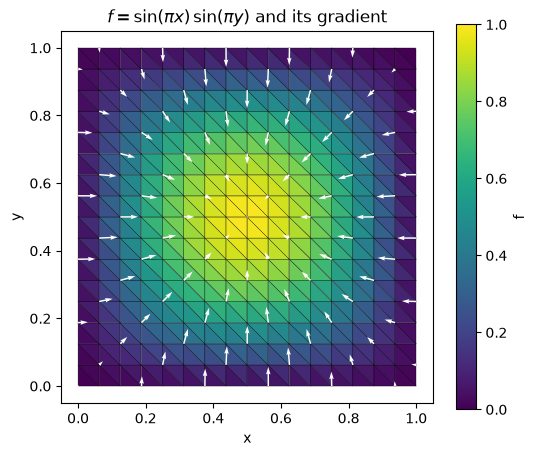

In [8]:
mesh = unit_square.load(subdivisions=4, device=device)
f, _, _ = smooth_field(mesh.points)
mesh.point_data["f"] = f
grad = compute_gradient_points_lsq(mesh, f)

fig, ax = plt.subplots(figsize=(6, 5))
mesh.draw(point_scalars="f", alpha_points=0.0, ax=ax, show=False)
p, g = mesh.points.cpu()[::3], grad.cpu()[::3]
ax.quiver(p[:, 0], p[:, 1], g[:, 0], g[:, 1], color="white", scale=60, width=0.004)
ax.set_title(r"$f = \sin(\pi x)\,\sin(\pi y)$ and its gradient")
plt.show()

### Irregular cells

Simulation meshes are rarely regular. `perturbed_grid` moves each interior
point of a structured grid by a random offset, with a standard deviation of
`perturbation_scale`. The table compares the methods on grids of 21 x 21
points, for offsets up to 30% of the grid spacing:

- the gradient of the smooth field (both methods),
- the divergence of v = (x, y), whose exact value is 2 (both methods),
- the Laplacian of x² + y², whose exact value is 4 (DEC only).

The columns give the median and the largest error over interior points.

In [9]:
spacing = 1 / 20
print(
    "offset   gradient LSQ   gradient DEC   divergence LSQ  divergence DEC   Laplacian DEC"
)
print(
    "         median  max    median  max    median  max     median  max      median  max"
)
for fraction in [0.0, 0.05, 0.1, 0.2, 0.3]:
    # Built on the CPU, so that the random offsets do not depend on the device
    mesh = perturbed_grid.load(
        n_x=21, n_y=21, perturbation_scale=fraction * spacing, seed=0
    ).to(device)
    interior = ~boundary_mask(mesh)
    f, grad, _ = smooth_field(mesh.points)
    errors = [
        (compute_gradient_points_lsq(mesh, f) - grad).norm(dim=-1),
        (compute_gradient_points_dec(mesh, f) - grad).norm(dim=-1),
        (compute_divergence_points_lsq(mesh, mesh.points) - 2).abs(),
        (compute_divergence_points_dec(mesh, mesh.points) - 2).abs(),
        (compute_laplacian_points_dec(mesh, (mesh.points**2).sum(dim=-1)) - 4).abs(),
    ]
    row = "".join(
        f"  {e[interior].median():6.3f} {e[interior].max():6.2f} " for e in errors
    )
    print(f"{fraction:5.0%} {row}")

offset   gradient LSQ   gradient DEC   divergence LSQ  divergence DEC   Laplacian DEC
         median  max    median  max    median  max     median  max      median  max


   0%    0.017   0.02    0.017   0.02    0.000   0.00    0.000   0.00    0.000   0.00 
   5%    0.026   0.09    0.027   0.08    0.000   0.00    0.023   0.15    0.047   0.29 
  10%    0.042   0.19    0.042   0.17    0.000   0.00    0.055   0.76    0.110   1.52 
  20%    0.075   0.37    0.078   0.30    0.000   0.00    0.145  33.98    0.290  67.96 
  30%    0.108   0.49    0.115   0.40    0.000   0.00    0.374 208.29    0.748 416.58 


The table shows three things:

- The gradient errors of the two methods stay close to each other. Both grow
  with the offsets, to about six times the error on the regular grid.
- LSQ gives the exact divergence of a linear field on every mesh, because it
  fits a linear function.
- The DEC divergence and Laplacian are exact at the interior points of the
  regular grid, but their error grows quickly with the offsets. At 20% and
  30%, the largest errors are many times larger than the values themselves.

DEC divides by the dual cell volume of each point, and its edge weights come
from the angles of the cells. Cells with angles near 180 degrees make the
weights small or negative, and the result is inaccurate at those points. The
map shows the error of the DEC divergence at each point of the grid with 30%
offsets.

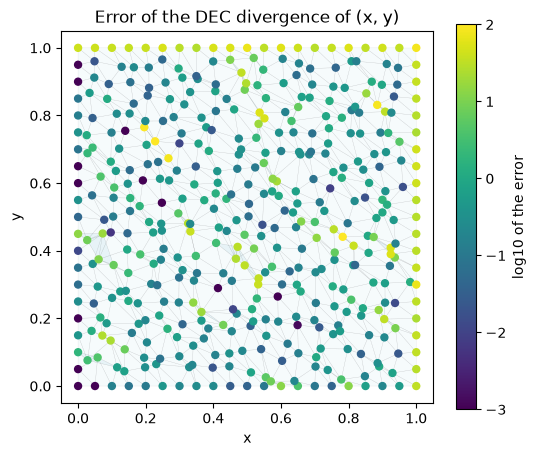

In [10]:
mesh = perturbed_grid.load(n_x=21, n_y=21, perturbation_scale=0.3 * spacing, seed=0)
error = (compute_divergence_points_dec(mesh, mesh.points) - 2).abs()

fig, ax = plt.subplots(figsize=(6, 5))
mesh.draw(ax=ax, show=False, alpha_cells=0.1, alpha_points=0.0)
dots = ax.scatter(
    *mesh.points.T, c=error.clamp(min=1e-3).log10(), vmin=-3, vmax=2, s=25, zorder=3
)
fig.colorbar(dots, ax=ax, label="log10 of the error")
ax.set_title("Error of the DEC divergence of (x, y)")
plt.show()

The yellow points have errors of 10 or more, five times the exact value. They
are scattered over the interior, and many boundary points have large errors
too.

### Which method to use

| Operator | LSQ | DEC |
|---|---|---|
| Gradient at points | `compute_gradient_points_lsq` | `compute_gradient_points_dec` (segments, triangles, tetrahedra) |
| Gradient at cells | `compute_gradient_cells_lsq` | none |
| Divergence | `compute_divergence_points_lsq`, `compute_divergence_cells_lsq` | `compute_divergence_points_dec` |
| Curl (3D space only) | `compute_curl_points_lsq`, `compute_curl_cells_lsq` | none |
| Laplacian | none | `compute_laplacian_points_dec` |

All of these functions are in `physicsnemo.mesh.calculus`, and they all work
with autograd.

- Use LSQ by default. It works at points and at cells, on fields of any shape,
  on any manifold dimension, and it is less sensitive to cell shape.
- Use DEC for the Laplacian, which has no LSQ version, and when you need the
  operators of a finite-element discretization (the cotangent weights).
  Check the quality of the mesh first (see
  [Tutorial 7](tutorial_7_quality_repair.ipynb)): the DEC divergence and
  Laplacian need cells without very large angles.
- With either method, expect larger errors at boundary points. Leave them out
  of a loss, or give them a lower weight, unless you have checked them.

## 3. Divergence and curl

Divergence measures the net outflow of a vector field at a point, and it
appears in every conservation law. For v = (x, y), the divergence is 2. For
the rotation v = (-y, x), it is 0.

In [11]:
mesh = unit_square.load(subdivisions=5, device=device)
x, y = mesh.points[:, 0], mesh.points[:, 1]

source = torch.stack([x, y], dim=-1)
rotation = torch.stack([-y, x], dim=-1)
print(f"div(x, y):  mean {compute_divergence_points_lsq(mesh, source).mean():.4f}")
print(f"div(-y, x): mean {compute_divergence_points_lsq(mesh, rotation).mean():.4f}")

div(x, y):  mean 2.0000
div(-y, x): mean 0.0000


Curl measures the local rotation of a vector field. It needs three spatial
dimensions, so the curl functions raise a `ValueError` on 2D meshes. The
rotation v = (-y, x, 0) about the z axis has curl (0, 0, 2) everywhere. Here,
it is computed on a tetrahedral mesh of a cube.

In [12]:
cube = cube_volume.load(subdivisions=8, device=device)
x, y, z = cube.points.unbind(dim=-1)
rotation = torch.stack([-y, x, torch.zeros_like(z)], dim=-1)

curl = compute_curl_points_lsq(cube, rotation)
print(f"Mesh: {cube}")
print(f"curl shape: {tuple(curl.shape)}")
print(f"Mean curl: {curl.mean(dim=0)}")

Mesh: Mesh[n_manifold_dims=3, n_spatial_dims=3](n_points=729, n_cells=3072)
curl shape: (729, 3)
Mean curl: tensor([0.0000, 0.0000, 2.0000], device='cuda:0')


### Vector identities hold only approximately

In continuous calculus, curl(grad f) = 0 and div(curl v) = 0 for any smooth
f and v. The LSQ operators do not satisfy these identities exactly. Each LSQ
step makes an error that changes from point to point, and the next step
differentiates that error. The residual stays the same size when you refine
the mesh. The test uses f = x²y + yz² + xz and v = (yz, x², xyz):

In [13]:
print("subdivisions  points   |curl grad f| max      |div curl v| max")
print("                       interior  boundary    interior  boundary")
for subdivisions in [4, 8, 12]:
    cube = cube_volume.load(subdivisions=subdivisions, device=device)
    on_boundary = boundary_mask(cube)
    x, y, z = cube.points.unbind(dim=-1)
    f = x**2 * y + y * z**2 + x * z
    v = torch.stack([y * z, x**2, x * y * z], dim=-1)

    curl_grad = compute_curl_points_lsq(cube, compute_gradient_points_lsq(cube, f))
    div_curl = compute_divergence_points_lsq(cube, compute_curl_points_lsq(cube, v))
    residuals = [curl_grad.norm(dim=-1), div_curl.abs()]
    row = "".join(
        f"{r[~on_boundary].max():10.3f}{r[on_boundary].max():10.3f}  "
        for r in residuals
    )
    print(f"{subdivisions:12d} {cube.n_points:7d}   {row}")

subdivisions  points   |curl grad f| max      |div curl v| max
                       interior  boundary    interior  boundary
           4     125        0.161     0.377       0.136     0.551  


           8     729        0.189     0.413       0.140     0.561  


          12    2197        0.201     0.433       0.141     0.564  


The residuals are about 0.2 at interior points and about 0.4 to 0.6 at
boundary points, at every resolution. Do not use these identities to test a
pipeline, and do not expect a vector field built as a gradient to have zero
curl to machine precision.

## 4. The Laplacian

The Laplacian, the divergence of the gradient, appears in diffusion, heat
transfer, and pressure equations. `compute_laplacian_points_dec` computes it
with the cotangent formula of DEC. It uses the sign convention of analysis:
the Laplacian of x² + y² is +4, and the Laplacian of a function at a local
maximum is negative. Some geometry-processing codes use the opposite sign.

In [14]:
mesh = unit_square.load(subdivisions=5, device=device)
interior = ~boundary_mask(mesh)
f, _, laplacian_exact = smooth_field(mesh.points)

bowl = compute_laplacian_points_dec(mesh, (mesh.points**2).sum(dim=-1))
wave = compute_laplacian_points_dec(mesh, f)
print(f"Laplacian of x^2 + y^2, interior: mean {bowl[interior].mean():.4f}")
print(
    f"Laplacian of x^2 + y^2, boundary: from {bowl[~interior].min():.1f} "
    f"to {bowl[~interior].max():.1f}"
)
print(
    f"Laplacian of f: mean error {(wave - laplacian_exact)[interior].abs().mean():.4f}"
)
print(f"  (|Laplacian of f| has mean {laplacian_exact[interior].abs().mean():.2f})")

Laplacian of x^2 + y^2, interior: mean 4.0000
Laplacian of x^2 + y^2, boundary: from -252.0 to 4.0
Laplacian of f: mean error 0.0068
  (|Laplacian of f| has mean 8.51)


The values at boundary points are not reliable: here they range from -252 to
4. The formula at a boundary point leaves out the flux through the boundary. A loss or a feature that uses the
DEC Laplacian must leave out the boundary points, or treat them with a
boundary condition.

The Laplacian works on meshes of any manifold dimension. On a tetrahedral mesh
of a cube, it is again exact at the interior points for a quadratic field,
and wrong at the boundary points.

In [15]:
cube = cube_volume.load(subdivisions=4, device=device)
on_boundary = boundary_mask(cube)
laplacian = compute_laplacian_points_dec(cube, (cube.points**2).sum(dim=-1))
print("Exact value: 6")
print(
    f"Interior points: from {laplacian[~on_boundary].min():.3f} to {laplacian[~on_boundary].max():.3f}"
)
print(
    f"Boundary points: from {laplacian[on_boundary].min():.3f} to {laplacian[on_boundary].max():.3f}"
)

Exact value: 6
Interior points: from 6.000 to 6.000
Boundary points: from -24.000 to -2.000


## 5. Gradients on surfaces: intrinsic and extrinsic

On a surface in 3D, a field can only change along the surface. Its intrinsic
gradient lies in the tangent plane. Its extrinsic gradient is the gradient of a
function of all three coordinates, and it can point out of the surface.
`compute_point_derivatives` returns the intrinsic gradient by default. Set
`gradient_type="extrinsic"`, or `"both"`, for the other one.

For the height h = z on the unit sphere, the extrinsic gradient is (0, 0, 1)
everywhere. The intrinsic gradient is its projection onto the tangent plane:
it is largest at the equator and zero at the poles.

In [16]:
sphere = sphere_icosahedral.load(subdivisions=3, device=device)
sphere.point_data["height"] = sphere.points[:, 2]

intrinsic = sphere.compute_point_derivatives(keys="height").point_data[
    "height_gradient"
]
extrinsic = sphere.compute_point_derivatives(
    keys="height", gradient_type="extrinsic"
).point_data["height_gradient"]

normals = sphere.point_normals
print(f"Mean extrinsic gradient: {extrinsic.mean(dim=0)}")
print(
    f"Largest |intrinsic . normal|: {(intrinsic * normals).sum(dim=-1).abs().max():.2e}"
)
print(
    f"Mean |extrinsic . normal|: {(extrinsic * normals).sum(dim=-1).abs().mean():.3f}"
)

Mean extrinsic gradient: tensor([0.0000, 0.0000, 1.0000], device='cuda:0')
Largest |intrinsic . normal|: 8.20e-08
Mean |extrinsic . normal|: 0.498


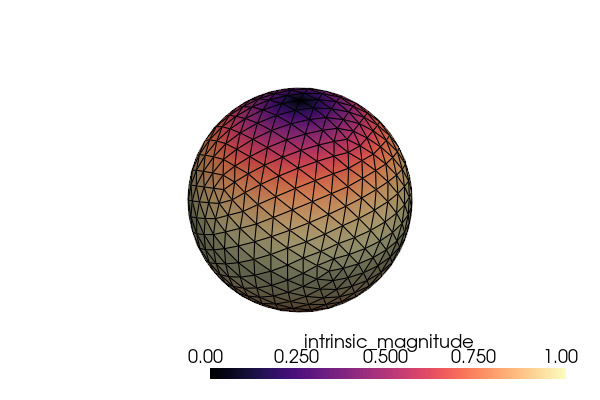

In [17]:
sphere.point_data["intrinsic_magnitude"] = intrinsic.norm(dim=-1)
_ = sphere.draw(point_scalars="intrinsic_magnitude", cmap="magma", alpha_points=0.0)

Normals, and the projection that they make possible, need codimension 1: a
curve in 2D or a surface in 3D. For a higher codimension, such as a curve in
3D, the intrinsic gradient estimates the tangent space from the neighbors of
each point. On a mesh that fills its space (codimension 0, for example a
triangle mesh in 2D), the two gradients are the same.

## 6. Curvature

Curvature describes the shape of a surface, and it is a useful input feature
for models of flow around a body. The library computes two curvatures at each
point, from the principal curvatures κ₁ and κ₂:

| Curvature | Formula | Property | Meshes |
|---|---|---|---|
| Gaussian, K | κ₁ κ₂ | Intrinsic: does not change when the surface bends without stretching | Any codimension |
| Mean, H | (κ₁ + κ₂) / 2 | Extrinsic: depends on how the surface sits in space | Codimension 1 |

For a sphere of radius r, K = 1/r² and H = 1/r.

In [18]:
radius = 2.0
sphere = sphere_icosahedral.load(radius=radius, subdivisions=4, device=device)
K = sphere.gaussian_curvature_vertices
H = sphere.mean_curvature_vertices
print(f"K: expected {1 / radius**2:.4f}, mean {K.mean():.4f}")
print(f"H: expected {1 / radius:.4f}, mean {H.mean():.4f}")

K: expected 0.2500, mean 0.2503
H: expected 0.5000, mean 0.5000


On the Stanford bunny, the Gaussian curvature is positive on the round parts
and negative at saddle-shaped regions, such as the neck and the base of the
ears.
The bunny is about 0.3 units across, so its curvatures are large numbers. The
color limits clip the extreme values.

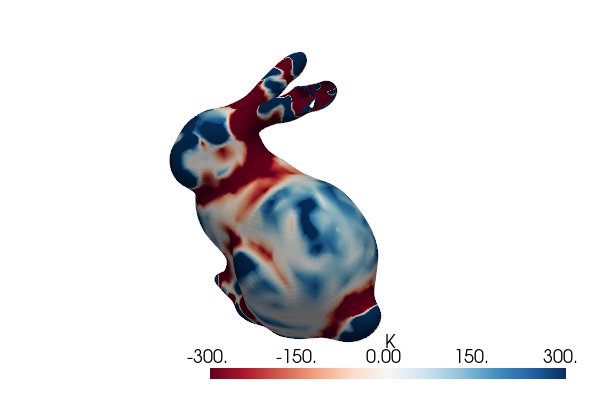

In [19]:
bunny = torch.load("assets/bunny.pt", weights_only=False).to(device)
bunny = bunny.subdivide(levels=2, filter="loop")
bunny.point_data["K"] = bunny.gaussian_curvature_vertices
_ = bunny.draw(
    point_scalars="K",
    cmap="RdBu",
    vmin=-300,
    vmax=300,
    show_edges=False,
    alpha_points=0.0,
)

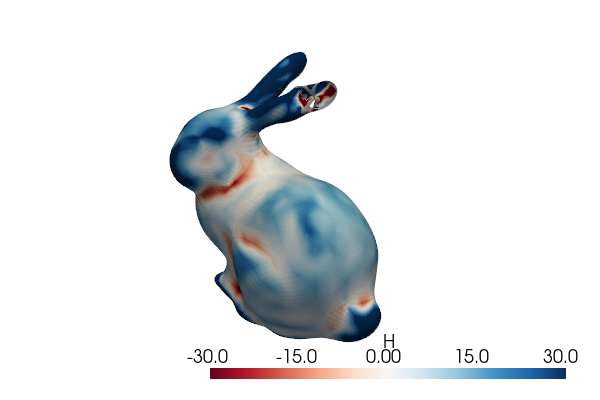

In [20]:
bunny.point_data["H"] = bunny.mean_curvature_vertices
_ = bunny.draw(
    point_scalars="H",
    cmap="RdBu",
    vmin=-30,
    vmax=30,
    show_edges=False,
    alpha_points=0.0,
)

The bunny mesh is not closed: it has a few holes. At the points on their
boundaries, the mean curvature is NaN by default, and the Gaussian curvature
measures the corner angle of the boundary, not the shape of the surface.

In [21]:
print(f"Points on the boundary: {boundary_mask(bunny).sum()}")
print(f"Points where H is NaN: {bunny.point_data['H'].isnan().sum()}")

Points on the boundary: 47
Points where H is NaN: 47


### The Gauss-Bonnet theorem

For a closed surface, the integral of the Gaussian curvature depends only on
the topology: it equals 2πχ, where χ = 2 - 2g is the Euler characteristic and
g is the number of handles. A sphere gives 4π, and a torus gives 0.

The discrete Gaussian curvature is the angle defect at a point divided by the
area of its dual cell. The sum of K times the dual cell areas therefore adds
up the angle defects, and on a closed mesh that sum equals 2πχ exactly, at any
resolution. The small differences below come from float32 rounding. A different total means that the mesh has another topology, for
example a hole or an extra handle. It does not measure the quality of the
cells.

In [22]:
sphere = sphere_icosahedral.load(subdivisions=4, device=device)
donut = torus.load(
    major_radius=1.0, minor_radius=0.3, n_major=64, n_minor=32, device=device
)
for name, surface, expected in [("sphere", sphere, 4 * math.pi), ("torus", donut, 0.0)]:
    total = (
        surface.gaussian_curvature_vertices * compute_dual_volumes_0(surface)
    ).sum()
    print(f"{name}: total K = {total:.4f}, expected {expected:.4f}")

sphere: total K = 12.5666, expected 12.5664
torus: total K = 0.0004, expected 0.0000


## 7. Differentiable operators in a physics loss

All operators in this tutorial are built from PyTorch operations, so autograd
flows through them. A physics-informed loss can therefore penalize the
residual of a PDE that a model's output must satisfy.

This example uses the Poisson equation, Δu = s, with the source
s = -2π² sin(πx) sin(πy). Its solution is u = sin(πx) sin(πy). Here, the
"prediction" is the exact solution plus noise, with `requires_grad=True`, as
for the output of a model.

In [23]:
torch.manual_seed(0)
mesh = unit_square.load(subdivisions=5, device=device)
interior = ~boundary_mask(mesh)
u_exact, _, source = smooth_field(mesh.points)

for noise in [0.0, 0.01]:
    u = (u_exact + noise * torch.randn_like(u_exact)).requires_grad_(True)
    residual = compute_laplacian_points_dec(mesh, u) - source
    loss = residual[interior].pow(2).mean()
    loss.backward()
    print(f"noise {noise}: loss {loss.item():.3e}, |d loss / d u| {u.grad.norm():.3e}")

noise 0.0: loss 6.690e-05, |d loss / d u| 3.732e-02
noise 0.01: loss 2.087e+03, |d loss / d u| 1.738e+04


The loss is small for the exact solution: what remains is the discretization
error of the Laplacian. Noise of 1% makes the loss about 30 million times
larger, because the Laplacian amplifies errors that change from point to
point. The gradient
`u.grad` tells an optimizer how to change each value to reduce the residual.

The same quantities also serve as input features. A per-point feature tensor
for a model of the bunny can combine normals and curvatures. The NaN values
of H at the boundary points must be replaced first:

In [24]:
features = torch.cat(
    [
        bunny.point_normals,
        bunny.gaussian_curvature_vertices.unsqueeze(-1),
        bunny.mean_curvature_vertices.nan_to_num(0.0).unsqueeze(-1),
    ],
    dim=-1,
)
print(f"Feature tensor: {tuple(features.shape)} (normal x, y, z, K, H)")

Feature tensor: (6358, 5) (normal x, y, z, K, H)


## Summary

- `mesh.compute_point_derivatives(keys=...)` adds `<key>_gradient` fields.
  For a vector field, the Jacobian has the derivative axis first.
- LSQ and DEC give nearly the same gradient. Both are exact for linear fields,
  and both lose accuracy at boundary points.
- Use LSQ by default. Use DEC for the Laplacian, and check the mesh quality
  first: the DEC divergence and Laplacian are inaccurate at badly shaped
  cells.
- The LSQ operators satisfy curl(grad f) = 0 and div(curl v) = 0 only
  approximately.
- The Laplacian uses the sign convention of analysis: Δ(x² + y²) = +4.
- Intrinsic gradients lie in the tangent space of a surface. Normals and mean
  curvature need codimension 1.
- The total angle defect of a closed mesh equals 2πχ exactly.
- All operators work with autograd.

## Next steps

- [Tutorial 6: Neighbors, Adjacency, and Spatial Queries](tutorial_6_neighbors_spatial.ipynb)
  finds neighbors on a mesh and samples fields at arbitrary points.
- API reference:
  [calculus](https://docs.nvidia.com/physicsnemo/latest/physicsnemo/api/mesh/calculus.html),
  [curvature](https://docs.nvidia.com/physicsnemo/latest/physicsnemo/api/mesh/curvature.html),
  and [geometry](https://docs.nvidia.com/physicsnemo/latest/physicsnemo/api/mesh/geometry.html).
- User Guide: [Using Meshes](https://docs.nvidia.com/physicsnemo/latest/user-guide/mesh/using_mesh.html).